# 02 — Exploratory Data Analysis (EDA)
**NeoStats DS Hackathon — Loan Application Refusal Prediction**

**Goal:** understand *which applications get refused* before modelling, and turn that into business insights backed by numbers.

| Section | Question |
|---|---|
| 1 | How many applications, and what is the refusal rate? |
| 2 | Refusal rate by product, channel, loan purpose, client type |
| 3 | Refusal rate by income band, age band, employment band |
| 4 | Credit-history and credit-score signals |
| 5 | Volume and refusal-rate trend over time |
| 6 | Numeric features most associated with refusal |
| 7 | **Business insights** (each with a number, interpretation and lender relevance) |

**Input:** `model_table.parquet` from notebook 01.

> EDA here is *descriptive* and uses all decided applications. **No modelling decision** (feature choice, threshold) is taken from validation/test/OOT data in this notebook — those decisions happen in notebook 03 on the validation set.
> Correlation is not causation: a high refusal rate in a segment shows *association*, not that the segment *causes* refusal.

In [1]:
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

ON_KAGGLE = Path("/kaggle/input").exists()
IN_DIRS = [Path("/kaggle/input"), Path("/kaggle/working")] if ON_KAGGLE else [Path("../outputs"), Path("outputs")]
OUT_DIR = Path("/kaggle/working") if ON_KAGGLE else Path("../outputs")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def find(name):
    for d in IN_DIRS:
        if d.exists():
            hits = sorted(d.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found under {IN_DIRS}. On Kaggle: Add Input -> Your Work -> Notebooks -> your notebook 01.")

PATH = find("model_table.parquet")
df = pd.read_parquet(PATH)
print("Loaded:", PATH, "| shape:", df.shape)

# ---- chart style: one blue for single-series bars, grey reference line, recessive grid ----
BLUE, ORANGE, GREY, INK, INK2 = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0",
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": "#ebeae6",
    "grid.linewidth": 0.8, "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left",
})
OVERALL = df["REFUSED"].mean()

Loaded: /kaggle/input/notebooks/sandrapc/data-prep/model_table.parquet | shape: (1327459, 60)


## 1. Headline numbers

In [2]:
print(f"Decided applications : {len(df):,}")
print(f"Distinct clients     : {df['SK_ID_CURR'].nunique():,}")
print(f"Refused              : {df['REFUSED'].sum():,}")
print(f"Approved             : {(1 - df['REFUSED']).sum():,}")
print(f"Overall refusal rate : {OVERALL:.2%}")
print(f"Applications per client (median): {df.groupby('SK_ID_CURR').size().median():.0f}")

Decided applications : 1,327,459
Distinct clients     : 338,402
Refused              : 290,678
Approved             : 1,036,781
Overall refusal rate : 21.90%
Applications per client (median): 3


## Helper functions
`rate_table` gives, for each value of a column: number of applications, share of volume, refusal rate, and **lift** (= segment refusal rate ÷ overall refusal rate; 2.0 means twice as likely to be refused as average). Tiny segments (< 0.5% of applications) are folded into "Other" so they cannot produce misleading extreme rates.

In [3]:
def rate_table(col, data=None, min_share=0.005, order=None):
    data = df if data is None else data
    s = data[col].astype("object").fillna("Missing")
    t = data.groupby(s, observed=True)["REFUSED"].agg(applications="size", refusal_rate="mean")
    t["share"] = t["applications"] / t["applications"].sum()
    small = t["share"] < min_share
    if small.sum() >= 1:
        other = data.loc[s.isin(t.index[small]), "REFUSED"]
        t = t[~small]
        t.loc["Other"] = [len(other), other.mean(), len(other) / len(data)]
    t["lift"] = t["refusal_rate"] / data["REFUSED"].mean()
    t = t.reindex([o for o in order if o in t.index] + [i for i in t.index if i not in order]) if order else t.sort_values("refusal_rate", ascending=False)
    return t

def plot_rate(t, title, fname, keep_order=False, min_n=1000):
    t = t[t["applications"] >= min_n]   # hide segments too small to read (still listed in the table)
    t = t if keep_order else t.sort_values("refusal_rate")
    t = t.iloc[::-1] if keep_order else t
    fig, ax = plt.subplots(figsize=(8, 0.38 * len(t) + 1.2))
    ax.barh(t.index.astype(str), t["refusal_rate"], color=BLUE, height=0.65)
    ax.axvline(OVERALL, color=GREY, ls="--", lw=1.2, label=f"overall refusal rate {OVERALL:.1%}")
    ax.legend(loc="lower right", frameon=False, fontsize=9)
    for y, (r, n) in enumerate(zip(t["refusal_rate"], t["applications"])):
        ax.text(r + 0.005, y, f"{r:.1%}  (n={n:,.0f})", va="center", fontsize=8.5, color=INK2)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    ax.set_xlim(0, min(1.0, t["refusal_rate"].max() * 1.35))
    ax.set_xlabel("Refusal rate")
    ax.grid(axis="y", visible=False)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(FIG_DIR / fname, dpi=130)
    plt.show()

def show(t):
    out = t.copy()
    out["share"] = (out["share"] * 100).round(1).astype(str) + "%"
    out["refusal_rate"] = (out["refusal_rate"] * 100).round(1).astype(str) + "%"
    out["lift"] = out["lift"].round(2)
    out["applications"] = out["applications"].astype(int)
    display(out)

## 2. Product, channel, loan purpose, client type

,applications,refusal_rate,share,lift
NAME_CONTRACT_TYPE,,,,
Other,31,100.0%,0.0%,4.57
Cash loans,478468,34.7%,36.0%,1.58
Revolving loans,147305,33.6%,11.1%,1.54
Consumer loans,701655,10.7%,52.9%,0.49


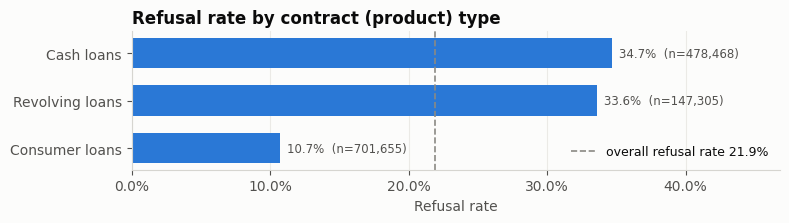

In [4]:
t_contract = rate_table("NAME_CONTRACT_TYPE"); show(t_contract)
plot_rate(t_contract, "Refusal rate by contract (product) type", "01_contract_type.png")

,applications,refusal_rate,share,lift
NAME_PORTFOLIO,,,,
Missing,40901,100.0%,3.1%,4.57
Cards,144510,32.3%,10.9%,1.48
Other,381,31.0%,0.0%,1.41
Cash,451740,30.8%,34.0%,1.41
POS,689927,9.2%,52.0%,0.42


,applications,refusal_rate,share,lift
NAME_PRODUCT_TYPE,,,,
walk-in,148400,51.0%,11.2%,2.33
x-sell,447850,24.6%,33.7%,1.12
Missing,731209,14.3%,55.1%,0.65


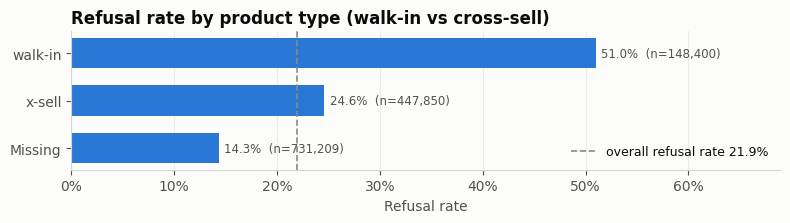

In [5]:
t_portfolio = rate_table("NAME_PORTFOLIO"); show(t_portfolio)
t_prodtype = rate_table("NAME_PRODUCT_TYPE"); show(t_prodtype)
plot_rate(t_prodtype, "Refusal rate by product type (walk-in vs cross-sell)", "02_product_type.png")

,applications,refusal_rate,share,lift
CHANNEL_TYPE,,,,
Other,6422,54.3%,0.5%,2.48
AP+ (Cash loan),53330,41.4%,4.0%,1.89
Contact center,40786,38.2%,3.1%,1.74
Credit and cash offices,439506,34.2%,33.1%,1.56
Country-wide,468549,14.0%,35.3%,0.64
Regional / Local,107743,10.5%,8.1%,0.48
Stone,211123,10.4%,15.9%,0.48


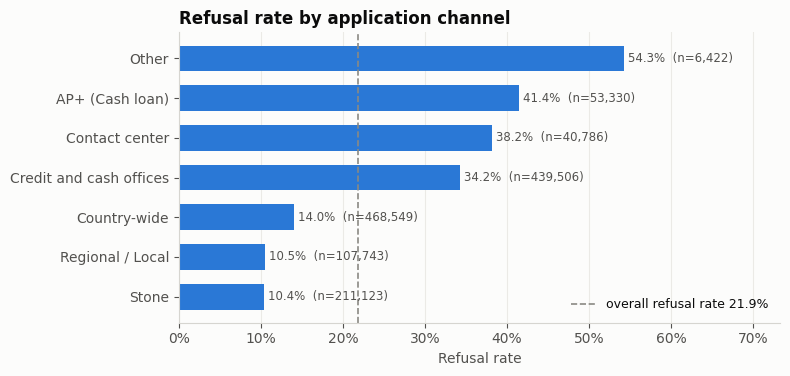

In [6]:
t_channel = rate_table("CHANNEL_TYPE"); show(t_channel)
plot_rate(t_channel, "Refusal rate by application channel", "03_channel.png")

,applications,refusal_rate,share,lift
NAME_CASH_LOAN_PURPOSE,,,,
Repairs,23098,62.4%,1.7%,2.85
Other,21233,62.3%,1.6%,2.85
Urgent needs,8264,56.8%,0.6%,2.59
Missing,410677,30.5%,30.9%,1.39
Not applicable,848991,14.7%,64.0%,0.67


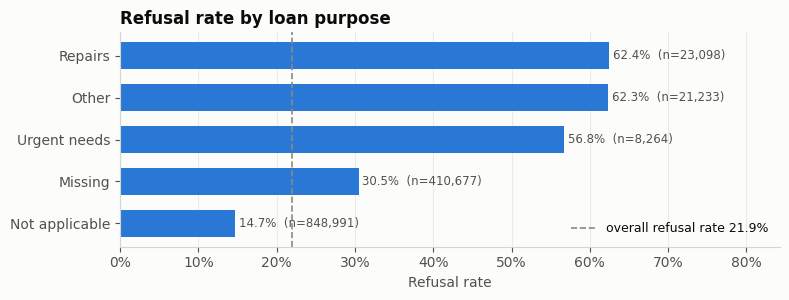

In [7]:
t_purpose = rate_table("NAME_CASH_LOAN_PURPOSE"); show(t_purpose)
plot_rate(t_purpose, "Refusal rate by loan purpose", "04_loan_purpose.png")

*Note:* most purposes are "Not applicable" (consumer/POS loans, where purpose does not apply) or "Missing" (`XNA`). Named purposes cover a small share of applications, so treat their rates as indicative.

,applications,refusal_rate,share,lift
NAME_CLIENT_TYPE,,,,
Other,932,38.0%,0.1%,1.73
Repeater,918704,28.4%,69.2%,1.30
Refreshed,112133,13.4%,8.4%,0.61
New,295690,4.9%,22.3%,0.22


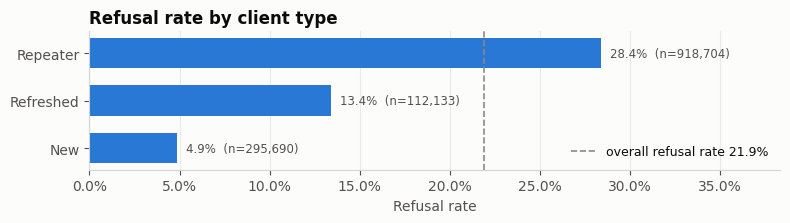

In [8]:
t_client = rate_table("NAME_CLIENT_TYPE"); show(t_client)
plot_rate(t_client, "Refusal rate by client type", "05_client_type.png")

In [9]:
# Is the client-type gap just product mix? Check the refusal rate WITHIN each contract type.
within = df.pivot_table(index="NAME_CLIENT_TYPE", columns="NAME_CONTRACT_TYPE", values="REFUSED", aggfunc="mean", observed=True)
display(within.style.format("{:.1%}"))
print("Share of each client type's applications that are consumer (POS) loans:")
print(pd.crosstab(df["NAME_CLIENT_TYPE"], df["NAME_CONTRACT_TYPE"], normalize="index")["Consumer loans"].round(3).to_string())

NAME_CONTRACT_TYPE,Cash loans,Consumer loans,Revolving loans
NAME_CLIENT_TYPE,,,
New,12.4%,3.6%,26.1%
Refreshed,18.3%,6.7%,30.8%
Repeater,37.1%,16.5%,34.5%


Share of each client type's applications that are consumer (POS) loans:
NAME_CLIENT_TYPE
New          0.902
Refreshed    0.549
Repeater     0.406


*Note on `NAME_PORTFOLIO = Missing` (XNA):* these records are refused 100% of the time — they look like applications stopped before a product was assigned. They are **1.7% of older data but 7.6% of the last 12 months**, so they also contribute to the higher OOT refusal rate. In notebook 03 we check how much the model relies on this (an "ablation" test).

## 3. Income, age and employment

,applications,refusal_rate,share,lift
INCOME_BAND,,,,
<100k,234953,18.6%,17.7%,0.85
100-150k,385603,21.1%,29.0%,0.96
150-200k,291954,22.6%,22.0%,1.03
200-300k,310407,23.7%,23.4%,1.08
300k+,104542,24.9%,7.9%,1.14


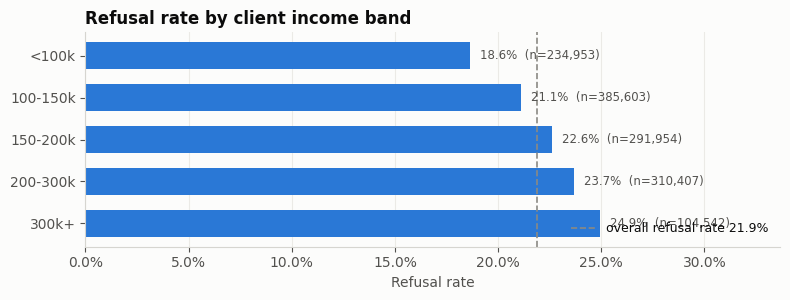

In [10]:
INCOME_ORDER = ["<100k", "100-150k", "150-200k", "200-300k", "300k+"]
t_income = rate_table("INCOME_BAND", order=INCOME_ORDER); show(t_income)
plot_rate(t_income, "Refusal rate by client income band", "06_income_band.png", keep_order=True)

,applications,refusal_rate,share,lift
AGE_BAND,,,,
<25,99631,21.2%,7.5%,0.97
25-34,344629,21.5%,26.0%,0.98
35-44,357214,21.3%,26.9%,0.97
45-54,287941,22.1%,21.7%,1.01
55+,238044,23.4%,17.9%,1.07


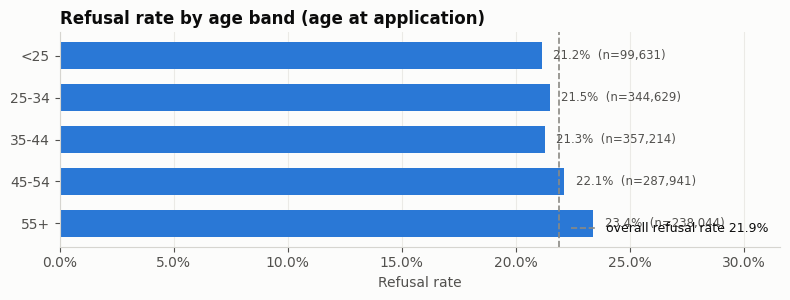

In [11]:
AGE_ORDER = ["<25", "25-34", "35-44", "45-54", "55+"]
t_age = rate_table("AGE_BAND", order=AGE_ORDER); show(t_age)
plot_rate(t_age, "Refusal rate by age band (age at application)", "07_age_band.png", keep_order=True)

,applications,refusal_rate,share,lift
EMPLOYMENT_BAND,,,,
<1y,117381,24.0%,8.8%,1.09
1-3y,210678,24.2%,15.9%,1.10
3-5y,142495,23.7%,10.7%,1.08
5-10y,194169,22.9%,14.6%,1.05
10y+,148836,22.3%,11.2%,1.02
No employment date,254167,21.0%,19.1%,0.96
Unknown,259733,18.0%,19.6%,0.82


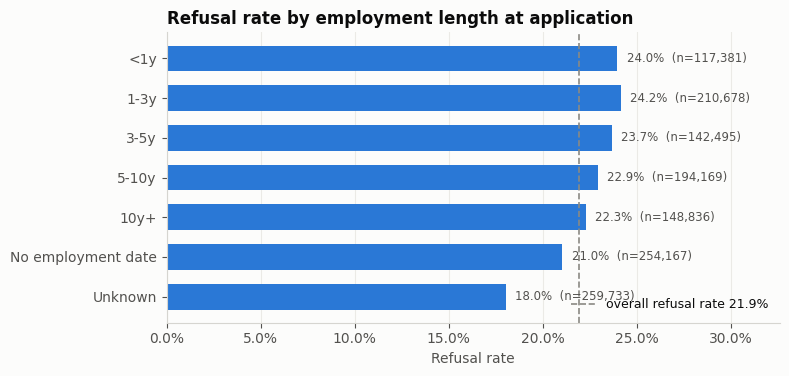

In [12]:
EMP_ORDER = ["<1y", "1-3y", "3-5y", "5-10y", "10y+", "No employment date", "Unknown"]
t_emp = rate_table("EMPLOYMENT_BAND", order=EMP_ORDER); show(t_emp)
plot_rate(t_emp, "Refusal rate by employment length at application", "08_employment_band.png", keep_order=True)

## 4. Credit history and credit scores

,applications,refusal_rate,share,lift
PRIOR_REFUSED_BUCKET,,,,
0,1009768,15.4%,76.1%,0.70
1,148886,33.3%,11.2%,1.52
2,68392,41.9%,5.2%,1.91
3,36373,49.5%,2.7%,2.26
4,21012,54.5%,1.6%,2.49
5+,43028,64.8%,3.2%,2.96


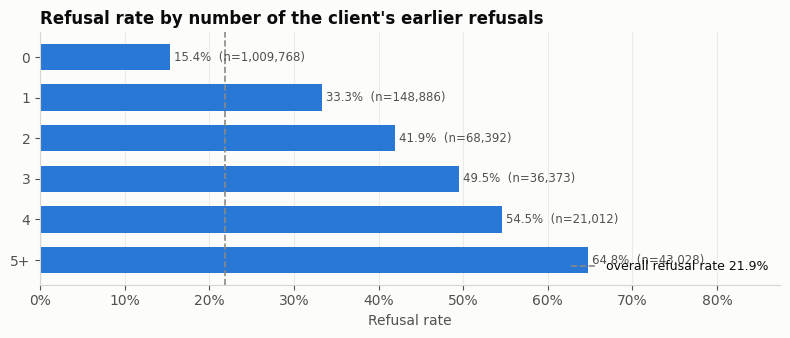

In [13]:
prior = df["PRIOR_REFUSED_COUNT"].clip(upper=5).astype(int).astype(str).replace({"5": "5+"})
t_prior = rate_table("PRIOR_REFUSED_BUCKET", data=df.assign(PRIOR_REFUSED_BUCKET=prior), order=["0", "1", "2", "3", "4", "5+"])
show(t_prior)
plot_rate(t_prior, "Refusal rate by number of the client's earlier refusals", "09_prior_refusals.png", keep_order=True)

,applications,refusal_rate,share,lift
EXT_DECILE,,,,
D1,132721,29.3%,10.0%,1.34
D2,132725,27.1%,10.0%,1.24
D3,132713,25.7%,10.0%,1.17
D4,132721,23.4%,10.0%,1.07
D5,132719,22.5%,10.0%,1.03
D6,132721,20.9%,10.0%,0.95
D7,132718,19.9%,10.0%,0.91
D8,132721,18.4%,10.0%,0.84
D9,132718,17.1%,10.0%,0.78


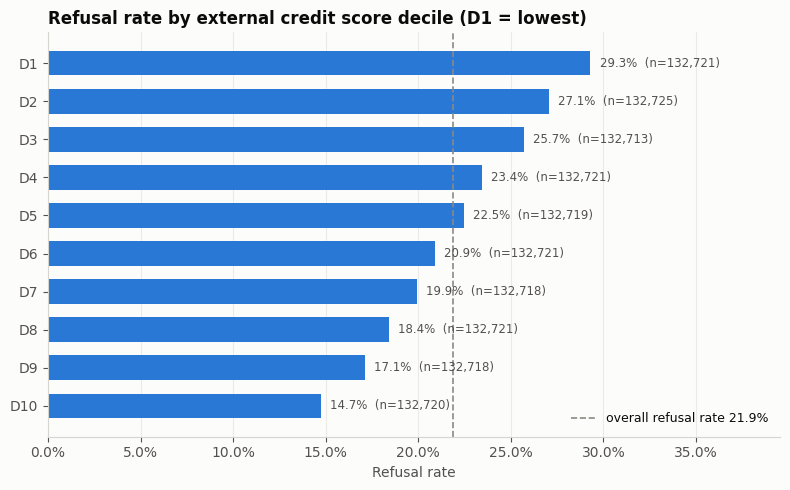

In [14]:
# External credit score: deciles of the mean of EXT_SOURCE_1/2/3 (D1 = lowest scores)
ext_dec = pd.qcut(df["EXT_SOURCE_MEAN"], 10, labels=[f"D{i}" for i in range(1, 11)])
t_ext = rate_table("EXT_DECILE", data=df.assign(EXT_DECILE=ext_dec), order=[f"D{i}" for i in range(1, 11)])
show(t_ext)
plot_rate(t_ext, "Refusal rate by external credit score decile (D1 = lowest)", "10_ext_source_decile.png", keep_order=True)

,applications,refusal_rate,share,lift
ATI_BAND,,,,
0 (no amount),86330,47.5%,6.5%,2.17
0-0.25x,190726,11.7%,14.4%,0.53
0.25-0.5x,264853,13.0%,20.0%,0.59
0.5-1x,298508,15.6%,22.5%,0.71
1-2x,235360,22.8%,17.7%,1.04
2-4x,150379,31.7%,11.3%,1.45
>4x,101303,44.3%,7.6%,2.02


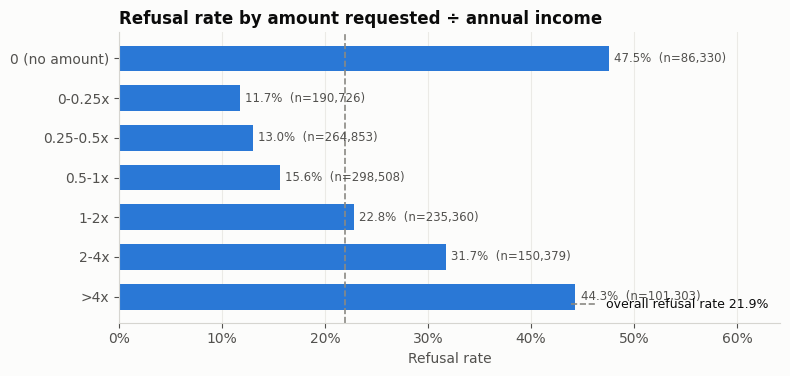

In [15]:
# Affordability: amount requested relative to annual income
ati = pd.cut(df["APP_TO_INCOME"], [-0.001, 0, 0.25, 0.5, 1, 2, 4, np.inf],
             labels=["0 (no amount)", "0-0.25x", "0.25-0.5x", "0.5-1x", "1-2x", "2-4x", ">4x"])
t_ati = rate_table("ATI_BAND", data=df.assign(ATI_BAND=ati),
                   order=["0 (no amount)", "0-0.25x", "0.25-0.5x", "0.5-1x", "1-2x", "2-4x", ">4x"])
show(t_ati)
plot_rate(t_ati, "Refusal rate by amount requested ÷ annual income", "11_app_to_income.png", keep_order=True)

## 5. Trend over time
Real dates are hidden, so time is measured as **months before the client's latest application** (`MONTHS_AGO`, from `DAYS_DECISION`). The shaded area is the out-of-time (OOT) window — the last 12 months. Volume and rate are shown in two separate panels (never two y-axes on one chart).

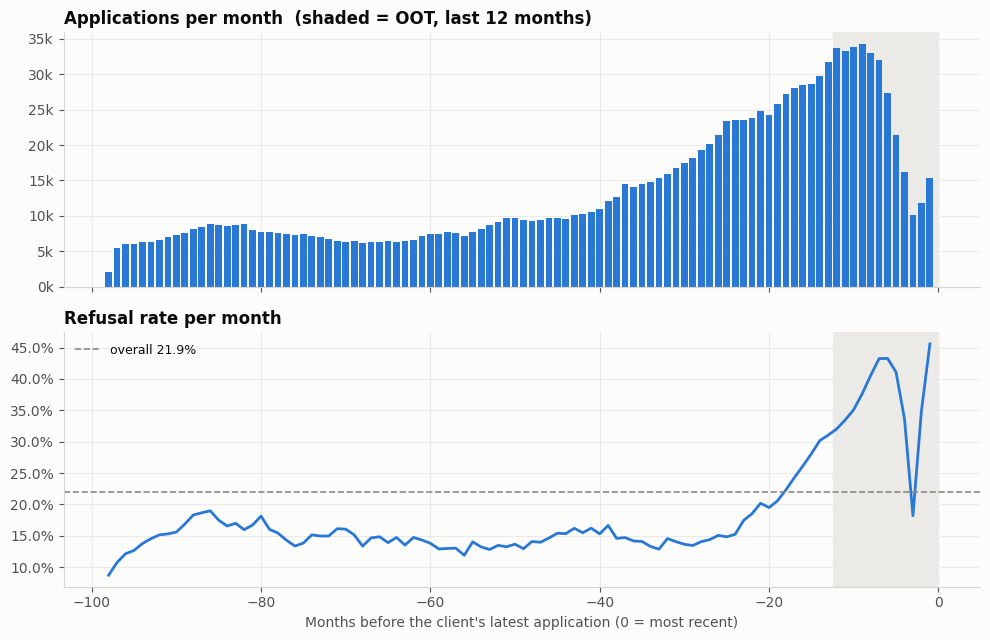

,applications,refusal_rate
0-1 yrs ago,"305,453",37.3%
1-2 yrs ago,"323,402",23.0%
2-3 yrs ago,"210,940",14.0%
3-4 yrs ago,"128,156",15.2%
4-5 yrs ago,"99,505",13.3%
5-6 yrs ago,"78,657",14.8%
6-7 yrs ago,"96,549",15.9%
7+ yrs ago,"84,797",15.4%


In [16]:
monthly = df.groupby("MONTHS_AGO")["REFUSED"].agg(applications="size", refusal_rate="mean").sort_index(ascending=False)
x = -monthly.index.values  # left = oldest, right = most recent

fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True)
a1.bar(x, monthly["applications"], color=BLUE, width=0.8)
a1.set_title("Applications per month  (shaded = OOT, last 12 months)")
a1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
a2.plot(x, monthly["refusal_rate"], color=BLUE, lw=2)
a2.axhline(OVERALL, color=GREY, ls="--", lw=1.2, label=f"overall {OVERALL:.1%}")
a2.legend(loc="upper left", frameon=False, fontsize=9)
a2.set_title("Refusal rate per month")
a2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
a2.set_xlabel("Months before the client's latest application (0 = most recent)")
for a in (a1, a2):
    a.axvspan(-12.5, 0, color="#ebeae6", zorder=0)
fig.tight_layout()
fig.savefig(FIG_DIR / "12_trend.png", dpi=130)
plt.show()

yearly = df.assign(YEAR_BACK=(df["YEARS_BEFORE_LATEST"]).astype(int).clip(upper=7)) \
           .groupby("YEAR_BACK")["REFUSED"].agg(applications="size", refusal_rate="mean")
yearly.index = [f"{i}-{i+1} yrs ago" if i < 7 else "7+ yrs ago" for i in yearly.index]
display(yearly.style.format({"refusal_rate": "{:.1%}", "applications": "{:,}"}))

**Why does the most recent year look so different?** Part of it is likely a real change (policy, product mix). Part may come from how the data is built: time counts back from each client's *latest* application, so the last 12 months contain many clients' most recent attempts, including quick re-applications after a refusal. Either way, the model will meet a different refusal rate on OOT than in training — we measure this in notebook 03.

In [17]:
# Did the product mix change in the most recent year? (explains part of the drift)
mix = (df.assign(PERIOD=np.where(df["SPLIT"] == "oot", "Last 12 months (OOT)", "Older (development)"))
         .pivot_table(index="NAME_CONTRACT_TYPE", columns="PERIOD", values="REFUSED", aggfunc=["size", "mean"], observed=True))
mix_share = mix["size"] / mix["size"].sum()
out = pd.concat({"share of applications": mix_share, "refusal rate": mix["mean"]}, axis=1)
display(out.style.format("{:.1%}"))

## 6. Numeric features most associated with refusal
Spearman correlation between each numeric feature and `REFUSED` (rank-based, so robust to outliers and skew). Calculated on the **training split only**, so this view cannot influence modelling with validation/test/OOT information. Positive = higher values go with more refusals.

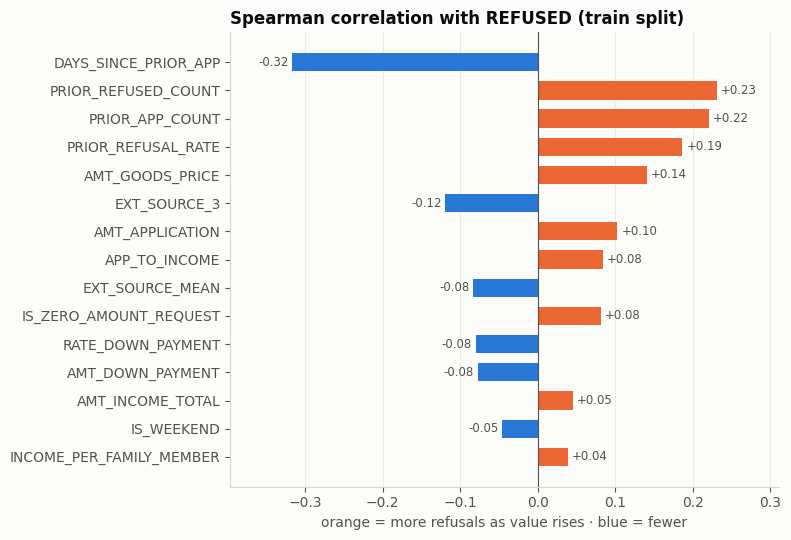

In [18]:
train = df[df["SPLIT"] == "train"]
num_cols = [c for c in train.select_dtypes("number").columns
            if c not in ["REFUSED", "SK_ID_PREV", "SK_ID_CURR", "DAYS_DECISION", "MONTHS_AGO", "YEARS_BEFORE_LATEST"]]
corr = train[num_cols].corrwith(train["REFUSED"], method="spearman").dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index).head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top.index, top.values, color=[ORANGE if v > 0 else BLUE for v in top.values], height=0.65)
ax.axvline(0, color=INK2, lw=0.8)
for y, v in enumerate(top.values):
    ax.text(v + (0.005 if v > 0 else -0.005), y, f"{v:+.2f}", va="center", ha="left" if v > 0 else "right", fontsize=8.5, color=INK2)
ax.set_xlim(top.min() - 0.08, top.max() + 0.08)
ax.grid(axis="y", visible=False)
ax.set_title("Spearman correlation with REFUSED (train split)")
ax.set_xlabel("orange = more refusals as value rises · blue = fewer")
fig.tight_layout(); fig.savefig(FIG_DIR / "13_correlations.png", dpi=130); plt.show()

## 7. Business insights
Every number below is calculated in this notebook (not typed by hand). Each insight has: **finding (with a number) → interpretation → why it matters to the lender**.

In [19]:
def r(t, k): return t.loc[k, "refusal_rate"]
insights = []

# 1. Product type
hi, lo = "Cash loans", "Consumer loans"
insights.append(("Product",
    f"{hi} are refused {r(t_contract, hi):.1%} of the time vs {r(t_contract, lo):.1%} for {lo} ({r(t_contract, hi) / r(t_contract, lo):.1f}x).",
    "Unsecured cash / revolving credit carries more risk than loans tied to a specific purchase at a store.",
    "Route cash and revolving applications to fuller review; consumer loans are good candidates for fast-track approval."))

# 2. Walk-in vs cross-sell
insights.append(("Channel / acquisition",
    f"Walk-in applications are refused {r(t_prodtype, 'walk-in'):.1%} of the time vs {r(t_prodtype, 'x-sell'):.1%} for cross-sell offers ({r(t_prodtype, 'walk-in') / r(t_prodtype, 'x-sell'):.1f}x).",
    "Cross-sell offers go to existing customers the lender has already screened; walk-ins are unknown.",
    "Growing pre-approved cross-sell reduces wasted underwriting effort; walk-ins need extra checks."))

# 3. Prior refusals
insights.append(("Credit history",
    f"Clients with no earlier refusal are refused {r(t_prior, '0'):.1%} of the time; after 1 earlier refusal it is {r(t_prior, '1'):.1%}, and after 5+ it is {r(t_prior, '5+'):.1%} ({r(t_prior, '5+') / r(t_prior, '0'):.1f}x).",
    "Repeated applications after a refusal rarely change the outcome - the client's situation has usually not changed.",
    "Flag repeat applicants early and guide them to a smaller amount or different product instead of a full re-review."))

# 4. External score
insights.append(("Credit score",
    f"Applicants in the lowest external-score decile are refused {r(t_ext, 'D1'):.1%} of the time vs {r(t_ext, 'D10'):.1%} in the highest ({r(t_ext, 'D1') / r(t_ext, 'D10'):.1f}x).",
    "External bureau-style scores summarise repayment behaviour elsewhere and line up with the lender's own decisions.",
    "A score threshold is a cheap first filter for pre-screening."))

# 5. Trend / drift
oot_rate, dev_rate = df.loc[df.SPLIT == "oot", "REFUSED"].mean(), df.loc[df.SPLIT != "oot", "REFUSED"].mean()
insights.append(("Trend over time",
    f"The refusal rate in the most recent 12 months is {oot_rate:.1%} vs {dev_rate:.1%} in older data ({oot_rate / dev_rate:.1f}x).",
    "Lending conditions or the applicant mix changed recently (cash-loan share also rose - see the product-mix table).",
    "A model trained on older data will under-predict refusals today: monitor drift and recalibrate thresholds regularly."))

# 6. Channel
big = t_channel[(t_channel["share"] >= 0.03) & (t_channel.index != "Other")]
ch_hi, ch_lo = big["refusal_rate"].idxmax(), big["refusal_rate"].idxmin()
insights.append(("Channel",
    f"Among channels with at least 3% of volume, '{ch_hi}' has the highest refusal rate ({r(t_channel, ch_hi):.1%}) and '{ch_lo}' the lowest ({r(t_channel, ch_lo):.1%}) - a {r(t_channel, ch_hi) / r(t_channel, ch_lo):.1f}x gap. 'Credit and cash offices' alone bring {t_channel.loc['Credit and cash offices', 'share']:.0%} of applications at {r(t_channel, 'Credit and cash offices'):.1%} refusal.",
    "Channels bring in very different applicant quality.",
    "Review acquisition through high-refusal channels - each refused application still costs underwriting time."))

# 7. Affordability
insights.append(("Affordability",
    f"Applications asking for more than 4x annual income are refused {r(t_ati, '>4x'):.1%} of the time vs {r(t_ati, '0.25-0.5x'):.1%} for 0.25-0.5x of income.",
    "Large requests relative to income signal affordability problems.",
    "Suggest a lower amount or longer term at the point of application to convert likely refusals into approvals."))

# 8. Client type
cash = within.loc[:, "Cash loans"]
insights.append(("Client type",
    f"Repeat clients are refused {r(t_client, 'Repeater'):.1%} of the time vs {r(t_client, 'New'):.1%} for new clients - and the gap holds within the same product (cash loans: {cash['Repeater']:.1%} vs {cash['New']:.1%}).",
    "Counter-intuitive: new clients mostly arrive through store (POS) loans, while 'repeaters' include clients re-applying after earlier refusals.",
    "Returning clients are not automatically low-risk; history (earlier refusals) matters more than simply being known."))

ins = pd.DataFrame(insights, columns=["area", "finding", "interpretation", "lender_relevance"])
ins.index = range(1, len(ins) + 1)
ins.to_csv(OUT_DIR / "eda_insights.csv", index_label="insight_no")
with pd.option_context("display.max_colwidth", None):
    display(ins)

,area,finding,interpretation,lender_relevance
1,Product,Cash loans are refused 34.7% of the time vs 10.7% for Consumer loans (3.2x).,Unsecured cash / revolving credit carries more risk than loans tied to a specific purchase at a store.,Route cash and revolving applications to fuller review; consumer loans are good candidates for fast-track approval.
2,Channel / acquisition,Walk-in applications are refused 51.0% of the time vs 24.6% for cross-sell offers (2.1x).,Cross-sell offers go to existing customers the lender has already screened; walk-ins are unknown.,Growing pre-approved cross-sell reduces wasted underwriting effort; walk-ins need extra checks.
3,Credit history,"Clients with no earlier refusal are refused 15.4% of the time; after 1 earlier refusal it is 33.3%, and after 5+ it is 64.8% (4.2x).",Repeated applications after a refusal rarely change the outcome - the client's situation has usually not changed.,Flag repeat applicants early and guide them to a smaller amount or different product instead of a full re-review.
4,Credit score,Applicants in the lowest external-score decile are refused 29.3% of the time vs 14.7% in the highest (2.0x).,External bureau-style scores summarise repayment behaviour elsewhere and line up with the lender's own decisions.,A score threshold is a cheap first filter for pre-screening.
5,Trend over time,The refusal rate in the most recent 12 months is 37.3% vs 17.3% in older data (2.2x).,Lending conditions or the applicant mix changed recently (cash-loan share also rose - see the product-mix table).,A model trained on older data will under-predict refusals today: monitor drift and recalibrate thresholds regularly.
6,Channel,"Among channels with at least 3% of volume, 'AP+ (Cash loan)' has the highest refusal rate (41.4%) and 'Stone' the lowest (10.4%) - a 4.0x gap. 'Credit and cash offices' alone bring 33% of applications at 34.2% refusal.",Channels bring in very different applicant quality.,Review acquisition through high-refusal channels - each refused application still costs underwriting time.
7,Affordability,Applications asking for more than 4x annual income are refused 44.3% of the time vs 13.0% for 0.25-0.5x of income.,Large requests relative to income signal affordability problems.,Suggest a lower amount or longer term at the point of application to convert likely refusals into approvals.
8,Client type,Repeat clients are refused 28.4% of the time vs 4.9% for new clients - and the gap holds within the same product (cash loans: 37.1% vs 12.4%).,"Counter-intuitive: new clients mostly arrive through store (POS) loans, while 'repeaters' include clients re-applying after earlier refusals.",Returning clients are not automatically low-risk; history (earlier refusals) matters more than simply being known.


### Variables that matter *less* than expected

In [20]:
for name, t in [("Income band", t_income), ("Age band", t_age)]:
    print(f"{name}: refusal rate ranges from {t['refusal_rate'].min():.1%} to {t['refusal_rate'].max():.1%} "
          f"(spread {100 * (t['refusal_rate'].max() - t['refusal_rate'].min()):.1f} percentage points)")

Income band: refusal rate ranges from 18.6% to 24.9% (spread 6.3 percentage points)
Age band: refusal rate ranges from 21.2% to 23.4% (spread 2.2 percentage points)


## Summary

* Overall refusal rate and volume (section 1).
* **Product and channel** drive the largest differences; **credit history** (earlier refusals) and **external scores** are strong signals.
* **Demographics** (income, age) show smaller spreads — useful context, but not the main story.
* **Refusal rate in the most recent 12 months is much higher** → drift; we expect lower precision/recall on OOT.
* All charts are saved in `figures/` for the presentation; the insights table is saved as `eda_insights.csv`.